In [1]:
import pandas as pd

df = pd.read_csv("result.csv")
df.head()

,topology,loss,algorithm,run,latency_ms,bytes_sent,bytes_read
0,single,0,slhdsa,1,173.52,484,34787
1,single,0,slhdsa,2,173.57,484,34787
2,single,0,slhdsa,3,173.18,484,34787
3,single,0,slhdsa,4,174.66,484,34787
4,single,0,slhdsa,5,173.95,484,34787


In [2]:
df["latency_ms"] = pd.to_numeric(df["latency_ms"], errors="coerce")
df = df.dropna(subset=["latency_ms"])
print(df.shape)
print(df["algorithm"].unique())
print(df["loss"].unique())
print(df["topology"].unique())

(3200, 7)
<StringArray>
['slhdsa', 'ecdsa', 'rsa', 'mldsa']
Length: 4, dtype: str
[0 1 3 5]
<StringArray>
['single', 'multi']
Length: 2, dtype: str


### Summary Table

In [ ]:
summary = df.groupby(["topology", "loss", "algorithm"]).agg(
    mean_ms=("latency_ms", "mean"),
    median_ms=("latency_ms", "median"),
    p95_ms=("latency_ms", lambda x: x.quantile(0.95)),
    max_ms=("latency_ms", "max"),
    bytes=("bytes_read", "first"),
).round(1).reset_index()

summary

,topology,loss,algorithm,mean_ms,median_ms,p95_ms,max_ms,bytes
0,multi,0,ecdsa,169.8,169.8,170.3,170.5,756
1,multi,0,mldsa,329.0,329.2,329.8,330.3,9119
2,multi,0,rsa,172.6,172.6,173.2,176.6,1337
3,multi,0,slhdsa,336.9,337.1,337.8,342.0,34787
4,multi,1,ecdsa,211.9,169.9,677.2,736.4,756
5,multi,1,mldsa,395.7,329.3,828.3,1500.6,9119
6,multi,1,rsa,219.9,172.8,675.7,791.4,1337
7,multi,1,slhdsa,511.9,484.0,991.4,1846.3,34787
8,multi,3,ecdsa,255.9,169.9,716.3,805.8,755
9,multi,3,mldsa,777.9,492.9,2130.5,6094.6,9119


### P95 tail latency vs packet loss

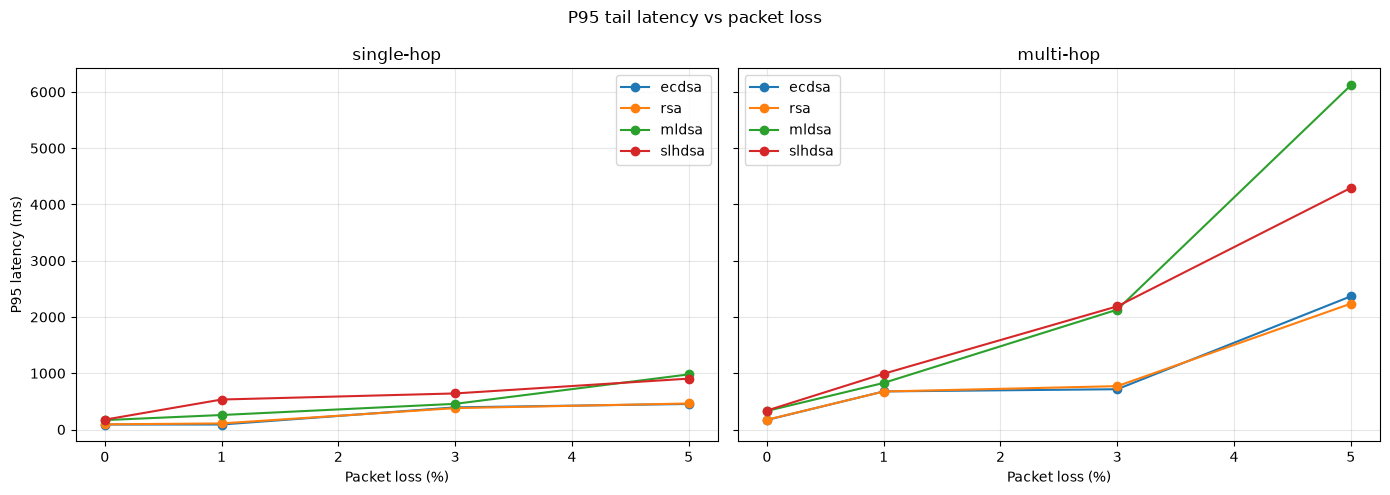

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, topo in zip(axes, ["single", "multi"]):
    d_topo = summary[summary["topology"] == topo]
    for algo in ["ecdsa", "rsa", "mldsa", "slhdsa"]:
        d = d_topo[d_topo["algorithm"] == algo].sort_values("loss")
        ax.plot(d["loss"], d["p95_ms"], marker="o", label=algo)
    ax.set_xlabel("Packet loss (%)")
    ax.set_title(f"{topo}-hop")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("P95 latency (ms)")
fig.suptitle("P95 tail latency vs packet loss")
plt.tight_layout()
plt.show()

### P95 tail latency vs packet loss

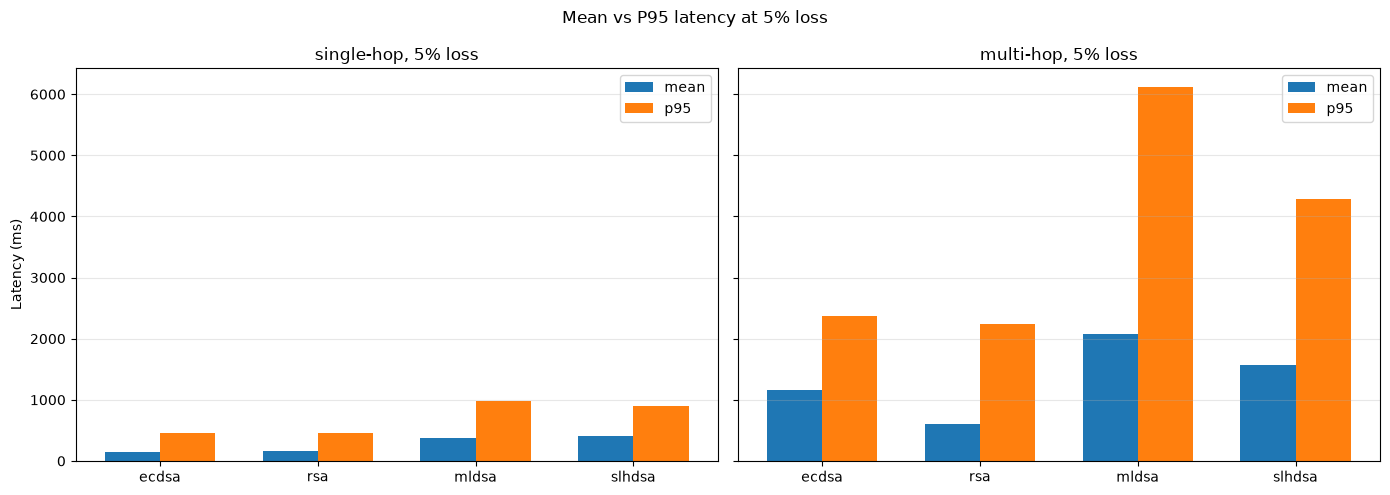

In [12]:
import matplotlib.pyplot as plt
import numpy as np

order = ["ecdsa", "rsa", "mldsa", "slhdsa"]
x = np.arange(len(order))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, topo in zip(axes, ["single", "multi"]):
    d = summary[(summary["topology"] == topo) & (summary["loss"] == 5)].set_index("algorithm")
    means = [d.loc[a, "mean_ms"] for a in order]
    p95s  = [d.loc[a, "p95_ms"] for a in order]
    ax.bar(x - width/2, means, width, label="mean")
    ax.bar(x + width/2, p95s, width, label="p95")
    ax.set_xticks(x)
    ax.set_xticklabels(order)
    ax.set_title(f"{topo}-hop, 5% loss")
    ax.grid(True, alpha=0.3, axis="y")
    ax.legend()

axes[0].set_ylabel("Latency (ms)")
fig.suptitle("Mean vs P95 latency at 5% loss")
plt.tight_layout()
plt.show()